In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("paper_style.mplstyle")
from paper_palette import FLASHLOAN_YES_COLOR, FLASHLOAN_NO_COLOR


In [2]:
CSV_FILES = {
    "syrupUSDC": "../from_dune/morpho_syrup_full_panel.csv",
    "sUSDS":     "../from_dune/morpho_susds_full_panel.csv",
    "sUSDe":     "../from_dune/morpho_aave_susde_full_panel.csv",
}

dfs = {name: pd.read_csv(path).assign(asset=name) for name, path in CSV_FILES.items()}
all_df = pd.concat(dfs.values(), ignore_index=True)

In [3]:
aave_flash_susde = pd.read_csv("../from_dune/flashloans/aave_flashloans.csv")
aave_whales = pd.read_csv("../input/aave_whales.csv")

# all sUSDe holders (not just whales), from your full panel data
susde_holders = all_df[all_df["asset"] == "sUSDe"]

In [4]:
susde_holders = susde_holders.copy()
susde_holders["did_flashloan"] = susde_holders["wallet"].isin(aave_flash_susde["initiator"])

n_total_holders = len(susde_holders)
n_flashloan_holders = susde_holders["did_flashloan"].sum()
pct_flashloan_holders = 100 * n_flashloan_holders / n_total_holders

print(f"{pct_flashloan_holders:.2f}% of all sUSDe holders have used a flashloan "
      f"({n_flashloan_holders} of {n_total_holders})")

4.16% of all sUSDe holders have used a flashloan (309 of 7433)


In [5]:
TOTAL_SUPPLY_SUSDE = all_df.loc[all_df["asset"] == "sUSDe", "total_YBS_exposure"].sum()

aave_whales["did_flashloan"] = aave_whales["wallet"].isin(aave_flash_susde["initiator"])
aave_whales["pct_of_supply"] = aave_whales["total_YBS_exposure"] / TOTAL_SUPPLY_SUSDE * 100

aave_whales_sorted = aave_whales.sort_values("pct_of_supply", ascending=False).reset_index(drop=True)

n_total_whales = len(aave_whales_sorted)
n_flashloan_whales = aave_whales_sorted["did_flashloan"].sum()
pct_flashloan_whales = 100 * n_flashloan_whales / n_total_whales

print(f"{pct_flashloan_whales:.1f}% of whales have used a flashloan "
      f"({n_flashloan_whales} of {n_total_whales})")

18.5% of whales have used a flashloan (15 of 81)


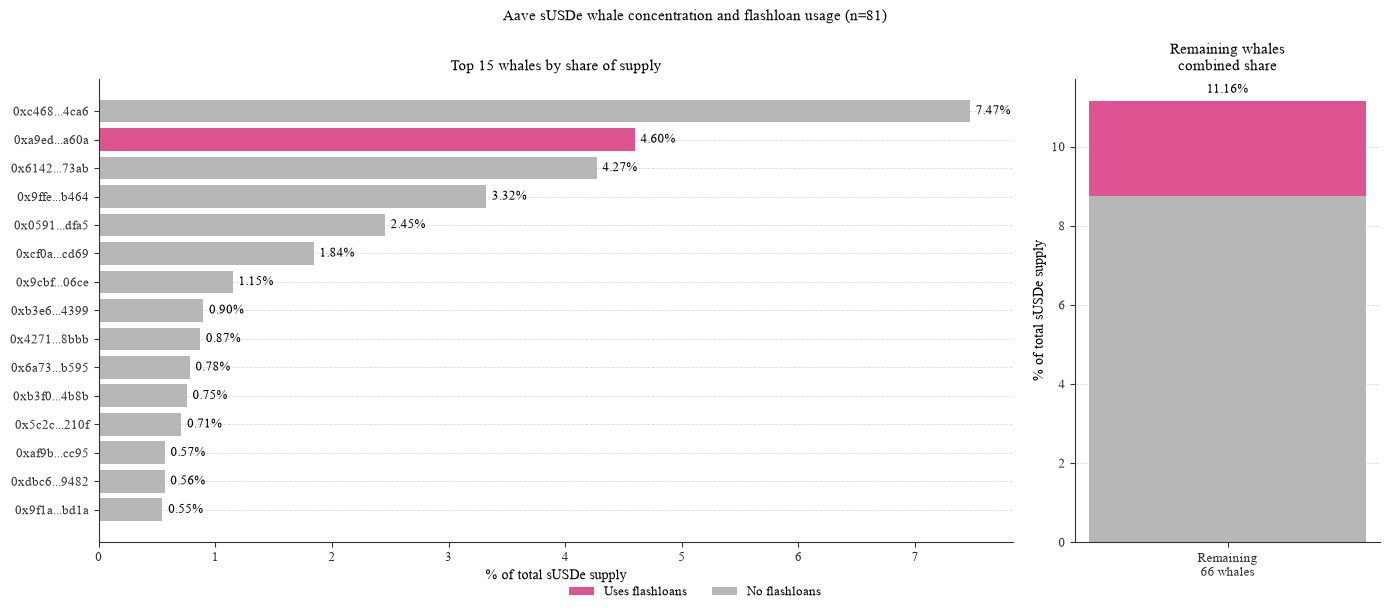

In [6]:
TOP_N = 15
top = aave_whales_sorted.head(TOP_N).copy()
rest = aave_whales_sorted.iloc[TOP_N:].copy()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [3, 1]})

# --- Left panel: top 15 whales, clearly labeled ---
colors_top = top["did_flashloan"].map({True: FLASHLOAN_YES_COLOR, False: FLASHLOAN_NO_COLOR})

ax1.barh(range(len(top)), top["pct_of_supply"], color=colors_top)
ax1.set_yticks(range(len(top)))
ax1.set_yticklabels([f"{w[:6]}...{w[-4:]}" for w in top["wallet"]], fontsize=9)
ax1.invert_yaxis()

for i, v in enumerate(top["pct_of_supply"]):
    ax1.text(v + 0.05, i, f"{v:.2f}%", va="center", fontsize=9)

ax1.set_xlabel("% of total sUSDe supply")
ax1.set_title(f"Top {TOP_N} whales by share of supply")

# --- Right panel: everyone else, summarized as one stacked bar ---
rest_flash = rest[rest["did_flashloan"]]["pct_of_supply"].sum()
rest_noflash = rest[~rest["did_flashloan"]]["pct_of_supply"].sum()

ax2.bar(["Remaining\n{} whales".format(len(rest))], [rest_noflash], color=FLASHLOAN_NO_COLOR, label="No flashloans")
ax2.bar(["Remaining\n{} whales".format(len(rest))], [rest_flash], bottom=[rest_noflash], color=FLASHLOAN_YES_COLOR, label="Uses flashloans")

ax2.set_ylabel("% of total sUSDe supply")
ax2.set_title("Remaining whales\ncombined share")
ax2.text(0, rest_noflash + rest_flash + 0.2, f"{rest_noflash + rest_flash:.2f}%", ha="center", fontsize=9)

n_total = len(aave_whales_sorted)
n_flash = aave_whales_sorted["did_flashloan"].sum()
pct_flash = 100 * n_flash / n_total

fig.suptitle(
    f"Aave sUSDe whale concentration and flashloan usage (n={n_total})",
    fontsize=11,
)

handles = [
    plt.Rectangle((0, 0), 1, 1, color=FLASHLOAN_YES_COLOR, label="Uses flashloans"),
    plt.Rectangle((0, 0), 1, 1, color=FLASHLOAN_NO_COLOR, label="No flashloans"),
]
fig.legend(handles=handles, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.02))

plt.tight_layout()
plt.savefig("../output/aave_whale_top15_plus_rest.png", dpi=300, bbox_inches="tight")
plt.show()

In [7]:
morpho_flash = {
    "sUSDe":     pd.read_csv("../from_dune/flashloans/morpho_flashloans_susde.csv"),
    "sUSDS":     pd.read_csv("../from_dune/flashloans/morpho_flashloans_susds.csv"),
    "syrupUSDC": pd.read_csv("../from_dune/flashloans/morpho_flashloans_syrup.csv"),
}

In [8]:
morpho_whales = pd.read_csv("../input/morpho_whales.csv")

total_supply_by_token = all_df.groupby("asset")["total_YBS_exposure"].sum()
print(total_supply_by_token)

asset
sUSDS        4.005787e+09
sUSDe        2.121045e+09
syrupUSDC    1.216483e+09
Name: total_YBS_exposure, dtype: float64


In [9]:
morpho_whale_results = {}

for token, flash_df in morpho_flash.items():
    whales_this_token = morpho_whales[morpho_whales["asset"] == token].copy()
    whales_this_token["did_flashloan"] = whales_this_token["wallet"].isin(flash_df["caller"])
    whales_this_token["pct_of_supply"] = (
        whales_this_token["total_YBS_exposure"] / total_supply_by_token[token] * 100
    )
    whales_this_token = whales_this_token.sort_values("pct_of_supply", ascending=False).reset_index(drop=True)
    morpho_whale_results[token] = whales_this_token

In [10]:
for token, df in morpho_whale_results.items():
    n_total = len(df)
    n_flash = df["did_flashloan"].sum()
    pct_flash = 100 * n_flash / n_total if n_total else 0
    print(f"{token}: {pct_flash:.1f}% of whales flashloan ({n_flash} of {n_total})")

sUSDe: 0.0% of whales flashloan (0 of 11)
sUSDS: 0.0% of whales flashloan (0 of 14)
syrupUSDC: 0.0% of whales flashloan (0 of 16)


In [11]:
for token, flash_df in morpho_flash.items():
    token_holders = all_df[all_df["asset"] == token]
    n_total_holders = len(token_holders)
    n_flashloan_holders = token_holders["wallet"].isin(flash_df["caller"]).sum()
    pct = 100 * n_flashloan_holders / n_total_holders

    print(f"{token}: {pct:.3f}% of all holders have used a flashloan "
          f"({n_flashloan_holders} of {n_total_holders})")

sUSDe: 0.013% of all holders have used a flashloan (1 of 7433)
sUSDS: 0.123% of all holders have used a flashloan (4 of 3242)
syrupUSDC: 0.000% of all holders have used a flashloan (0 of 2007)
